# **Member**

นาย ศุภณัฐ จันทร์เลข 6709616897 (Classification Data Analize & Training Logistic Regression mpdel)

นาย พัสกร พรพิฆเนส 6709681131 (Data Interpretation and Data visualization)

นาย พรินทาน หนุนชู 6709616673 (Classification Data Analize & Training Logistic Regression mpdel)

นาย ชัชวีร์ ไทยเจริญ 6709616426 (Data Interpretation and Data visualization)

นางสาว พิชฎา เฉลิมกลิ่น 6709616756 (Training Random Forest Model)

นางสาว ชิสาพัชร์ พิไลแสงสุรีย์ 6709620063 (Training KNN-neighbor)

นาย กรกฎ หาญมนตรี 6709616376 (Training LightGBM)

นาย จักรพงษ์ ปักษา 6709540055 (Training Neuron Network)

# **Problem Framing and Data Collection**

“ภาวะซึมเศร้า” (Depression) ภาวะทางอารมณ์ และ โรคทางจิตเวช ที่ส่งผลต่อความคิด ความรู้สึก พฤติกรรม และการใช้ชีวิตประจำวันของคน ๆ หนึ่ง ซึ่งมากกว่าความรู้สึก “เศร้า” ธรรมดา
จากการศึกษาของ Department of Mental Health, Thailand ผ่านการให้นักศึกษาจาก 33 มหาวิทยาลัย กว่า 14,621 คน ทำแบบสอบถาม PHQ-9(แบบสอบถามประเมินภาวะซึมเศร้า) พบว่า 31.4% มีภาวะซึมเศร้า และ 14.2% มีภาวะซึมเศร้าอย่างรุนแรง (major depressive disorder) ในกลุ่มคนเหล่านี้มักมีอาการวิตกขั้นรุนแรงทั้ง มองโลกในแง่ร้าย, ทำร้ายตัวเองซ้ำๆ, จนถึงขั้นพยายามฆ่าตัวตาย จากการศึกษาเพิ่มเติมภาวะซึมเศร้านั้นสามารถรักษาให้หายขาดได้หากได้รับการวินิจฉัยและบำบัดตามขั้นตอน ผู้พัฒนาจึงอยากที่จะพัฒนาอัลกอรึทึมที่สามารถช่วยประเมินผู้ที่มีภาวะซึมเศร้าได้ในขั้นต้นเพื่อที่จะได้ป้องกันและคำแนะนำที่เหมาะสมต่อนักศึกษากลุ่มนี้

Problem: ต้องการโมเดลที่จะทำให้สามารถตัดสินใจได้เบื้องต้นถึงโอกาสที่นักศึกษาคนหนึ่งจะมีภาวะซึมเศร้าจากปัจจัยต่างๆ

Data Collection: dataset ที่นำมาวิเคราะห์เป็นการรวมข้อมูลจากหลายๆแหล่งที่มีการเก็บตัวแปรที่ใกล้เคียงกันมาแปลงค่าให้อยู่ในสเกลมาตรฐานเดียวกัน จึงทำให้มีข้อกังวลเรื่องความน่าเชื่อถือของแหล่งข้อมูลแต่จากการประเมินแล้วทำให้ทราบว่าข้อมูลนี้มีการเตรียมข้อมูลมาก่อนนำมารวมกันจึงทำให้แน่ใจได้ว่าข้อมูลนี้มีประสิทธิภาพพอสมควร

resouces

สถิติการมีภาวะซึมเศร้าของนักศึกษาไทย: https://pubmed.ncbi.nlm.nih.gov/40103570/

ชุดข้อมูลที่ใช้: https://www.kaggle.com/datasets/sonia22222/students-mental-health-assessments?resource=download



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# **Data acquistion**

In [ ]:
#นำเข้าข้อมูล
from google.colab import files
uploaded = files.upload()

#แปลงข้อมูลเป็น Pandas
import pandas as pd
mental_health_data1=pd.read_csv('students_mental_health_survey.csv')

#เช็ค shape ก่อนเตรียมข้อมูล
print("shape:", mental_health_data1.shape)

#แสดงข้อมูลเบื้องต้นก่อนเตรียมข้อมูล
mental_health_data1.head(100)

Saving students_mental_health_survey.csv to students_mental_health_survey.csv
shape: (7022, 20)


,Age,Course,Gender,CGPA,Stress_Level,Depression_Score,Anxiety_Score,Sleep_Quality,Physical_Activity,Diet_Quality,Social_Support,Relationship_Status,Substance_Use,Counseling_Service_Use,Family_History,Chronic_Illness,Financial_Stress,Extracurricular_Involvement,Semester_Credit_Load,Residence_Type
0,25,Others,Male,3.56,3,3,2,Good,Moderate,Good,Moderate,Married,Never,Never,No,No,2,Moderate,17,On-Campus
1,24,Engineering,Female,2.44,0,3,0,Average,Low,Average,Low,Single,Occasionally,Occasionally,No,No,3,Low,27,On-Campus
2,19,Business,Female,3.74,4,0,3,Good,Low,Average,Moderate,In a Relationship,Never,Occasionally,No,No,4,High,15,On-Campus
3,19,Computer Science,Male,3.65,2,1,0,Average,Low,Average,Moderate,Single,NaN,Never,No,No,4,Moderate,20,Off-Campus
4,18,Business,Male,3.40,3,3,4,Good,Low,Average,High,Married,Never,Never,No,Yes,0,High,23,On-Campus
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,26,Law,Female,3.61,1,1,2,Poor,Low,Poor,Moderate,Married,Never,Never,No,No,4,Moderate,15,Off-Campus
96,21,Law,Male,4.00,1,0,4,Average,Low,Poor,Moderate,In a Relationship,Never,Never,No,No,5,Low,24,Off-Campus
97,22,Medical,Male,3.86,2,2,4,Average,Moderate,Poor,Moderate,Married,Never,Occasionally,Yes,No,2,Low,28,Off-Campus
98,19,Business,Male,3.12,2,1,2,Average,Moderate,Average,Low,Single,Never,Never,No,No,0,Low,17,On-Campus


# **Data Preparation**

In [ ]:
#เช็คตารางว่าง
mental_health_data1.isnull().sum()

,0
Age,0
Course,0
Gender,0
CGPA,12
Stress_Level,0
Depression_Score,0
Anxiety_Score,0
Sleep_Quality,0
Physical_Activity,0
Diet_Quality,0


In [ ]:
#กำจัดตารางที่ว่างออก
mental_health_data1_dropnull = mental_health_data1.dropna()
#เช็คข้อมูลหลังจากกำจัดตารางที่ว่าง
mental_health_data1_dropnull.isnull().sum()

,0
Age,0
Course,0
Gender,0
CGPA,0
Stress_Level,0
Depression_Score,0
Anxiety_Score,0
Sleep_Quality,0
Physical_Activity,0
Diet_Quality,0


In [ ]:
#เช็คข้อมูลที่ซ้ำ
mental_health_data1_dropnull.duplicated().sum()

np.int64(0)

In [ ]:
#กำหนดชื่อตัวแปรใหม่หลังคลีนแล้ว
df_clean = mental_health_data1_dropnull
print(df_clean.to_string())

      Age            Course  Gender  CGPA  Stress_Level  Depression_Score  Anxiety_Score Sleep_Quality Physical_Activity Diet_Quality Social_Support Relationship_Status Substance_Use Counseling_Service_Use Family_History Chronic_Illness  Financial_Stress Extracurricular_Involvement  Semester_Credit_Load Residence_Type
0      25            Others    Male  3.56             3                 3              2          Good          Moderate         Good       Moderate             Married         Never                  Never             No              No                 2                    Moderate                    17      On-Campus
1      24       Engineering  Female  2.44             0                 3              0       Average               Low      Average            Low              Single  Occasionally           Occasionally             No              No                 3                         Low                    27      On-Campus
2      19          Business  Female  3.7

In [ ]:
#Sort ตาม CourseและAge
df_clean = df_clean.sort_values(by=['Course', 'Age'], ascending=[True, True]).reset_index(drop=True)

#แปลงข้อมูลให้เป็นตัวเลข
df_clean['Gender'] = df_clean['Gender'].map({'Male': 0, 'Female': 1})

df_clean['Course'] = df_clean['Course'].map({
    'Business': 0,
    'Computer Science': 1,
    'Engineering': 2,
    'Law': 3,
    'Medical': 4,
    'Others': 5
})

df_clean['Sleep_Quality'] = df_clean['Sleep_Quality'].map({
    'Poor': 0,
    'Average': 1,
    'Good': 2
})

df_clean['Physical_Activity'] = df_clean['Physical_Activity'].map({
    'Low': 0,
    'Moderate': 1,
    'High': 2
})

df_clean['Diet_Quality'] = df_clean['Diet_Quality'].map({
    'Poor': 0,
    'Average': 1,
    'Good': 2
})

df_clean['Social_Support'] = df_clean['Social_Support'].map({
    'Low': 0,
    'Moderate': 1,
    'High': 2
})

df_clean['Relationship_Status'] = df_clean['Relationship_Status'].map({
    'Single': 0,
    'In a Relationship': 1,
    'Married': 2
})

df_clean['Substance_Use'] = df_clean['Substance_Use'].map({
    'Never': 0,
    'Occasionally': 1,
    'Frequently': 2
})

df_clean['Counseling_Service_Use'] = df_clean['Counseling_Service_Use'].map({
    'Never': 0,
    'Occasionally': 1,
    'Frequently': 2
})

df_clean['Family_History'] = df_clean['Family_History'].map({'No': 0, 'Yes': 1})

df_clean['Chronic_Illness'] = df_clean['Chronic_Illness'].map({'No': 0, 'Yes': 1})

df_clean['Extracurricular_Involvement'] = df_clean['Extracurricular_Involvement'].map({
    'Low': 0,
    'Moderate': 1,
    'High': 2
})

df_clean['Residence_Type'] = df_clean['Residence_Type'].map({
    'On-Campus': 0,
    'Off-Campus': 1,
    'With Family' : 2
})

# **Data Interpretation and Data visualization**

In [ ]:
#เรียกดูสถิติเชิงพรรณาของคอลลัมม์ Stress Level, Depression Level, Anxiety Score
print(df_clean[['Stress_Level','Depression_Score','Anxiety_Score']].describe())

       Stress_Level  Depression_Score  Anxiety_Score
count   6995.000000       6995.000000    6995.000000
mean       2.429450          2.255182       2.302359
std        1.639079          1.624867       1.624339
min        0.000000          0.000000       0.000000
25%        1.000000          1.000000       1.000000
50%        2.000000          2.000000       2.000000
75%        4.000000          3.000000       4.000000
max        5.000000          5.000000       5.000000


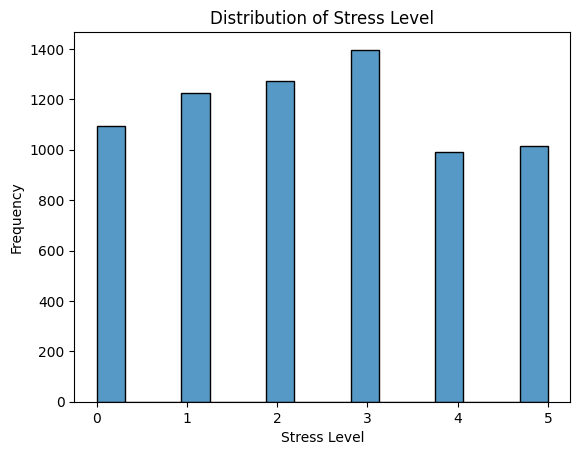

In [ ]:
#สร้างฮิสโตแกรมเพื่อดูการกระจายตัวของ Stress Level
sb.histplot(df_clean['Stress_Level'])
plt.title('Distribution of Stress Level')
plt.xlabel('Stress Level')
plt.ylabel('Frequency')
plt.show()

ผลการวิเคราะห์เบื้องต้น: นักศึกษาส่วนใหญ่มีระดับความเครียดอยู่ในระดับปานกลาง (ค่าเฉลี่ยราว 2–3) โดยมีการกระจายตัวสมมาตร ไม่มีความเครียดสูงหรือต่ำจนเกินไป ซึ่งแสดงให้เห็นว่าความเครียดของกลุ่มตัวอย่างอยู่ในช่วงที่สามารถจัดการได้

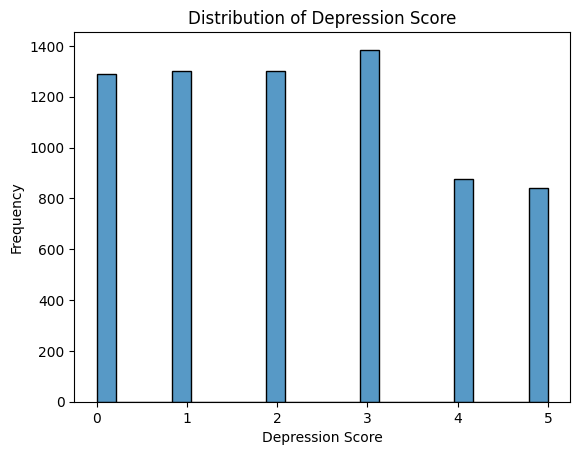

In [ ]:
#สร้างฮิสโตแกรมเพื่อดูการกระจายตัวของ Depression Score
sb.histplot(df_clean['Depression_Score'])
plt.title('Distribution of Depression Score')
plt.xlabel('Depression Score')
plt.ylabel('Frequency')
plt.show()

ผลการวิเคราะห์เบื้องต้น: ค่าคะแนนภาวะซึมเศร้า (Depression Score) มีแนวโน้มกระจายใกล้เคียงกับระดับความเครียด โดยนักศึกษาส่วนใหญ่มีภาวะซึมเศร้าอยู่ในระดับต่ำถึงปานกลาง และมีเพียงส่วนน้อยที่มีคะแนนซึมเศร้าสูง แสดงให้เห็นว่าภาวะทางอารมณ์โดยรวมยังอยู่ในระดับควบคุมได้

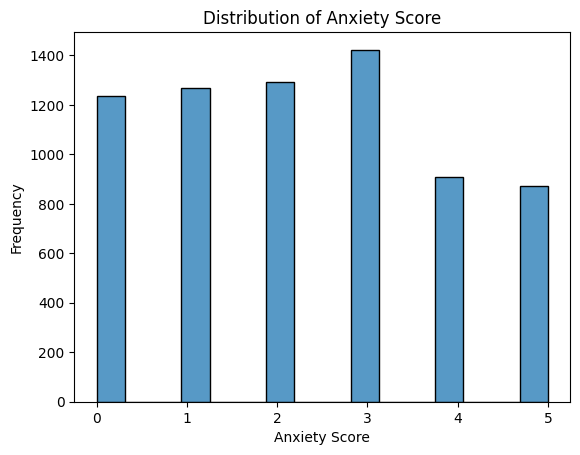

In [ ]:
#สร้างฮิสโตแกรมเพื่อดูการกระจายตัวของ Anxiety Score
sb.histplot(df_clean['Anxiety_Score'])
plt.title('Distribution of Anxiety Score')
plt.xlabel('Anxiety Score')
plt.ylabel('Frequency')
plt.show()

ผลการวิเคราะห์เบื้องต้น: การกระจายของคะแนนความวิตกกังวล (Anxiety Score) แสดงให้เห็นว่ากลุ่มตัวอย่างส่วนใหญ่มีความวิตกกังวลในระดับปานกลาง ซึ่งอาจเกิดจากแรงกดดันด้านการเรียนหรือการปรับตัวในชีวิตประจำวัน อย่างไรก็ตาม การมีความวิตกกังวลบางส่วนถือเป็นภาวะปกติในช่วงวัยนักศึกษา

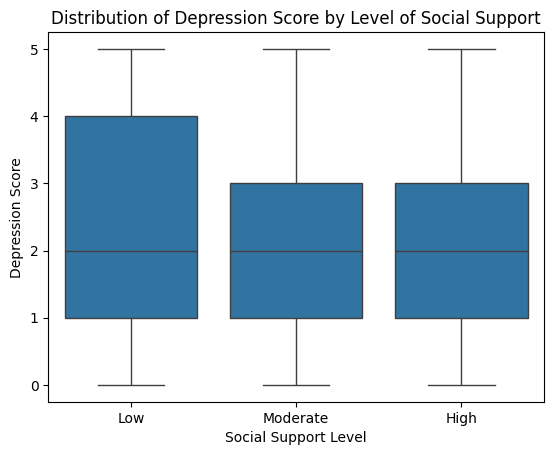

In [ ]:
#สร้างแผนภาพกล่องเพื่อดูการกระจายของ Depression Score
lb = sb.boxplot(data=df_clean, x='Social_Support', y='Depression_Score')
plt.title('Distribution of Depression Score by Level of Social Support')
plt.xlabel('Social Support Level')
plt.ylabel('Depression Score')

lb.set_xticks(np.arange(len(lb.get_xticklabels())))
lb.set_xticklabels(['Low', 'Moderate', 'High'])

plt.show()

ผลการวิเคราะห์เบื้องต้น: จากกราฟ boxplot แสดงการกระจายของคะแนนภาวะซึมเศร้า (Depression Score) จำแนกตามระดับการได้รับการสนับสนุนทางสังคม (Social Support) พบว่ากลุ่มที่ได้รับการสนับสนุนทางสังคมในระดับต่ำมีค่าภาวะซึมเศร้าสูงกว่าและกระจายกว้างกว่ากลุ่มที่ได้รับการสนับสนุนระดับปานกลางหรือสูง ขณะที่กลุ่มที่มีการสนับสนุนทางสังคมสูงมีค่าของภาวะซึมเศร้าต่ำกว่าอย่างชัดเจน ซึ่งสะท้อนให้เห็นแนวโน้มว่าการได้รับการสนับสนุนจากสังคมหรือเพื่อนมีส่วนช่วยลดภาวะซึมเศร้าในนักศึกษาได้

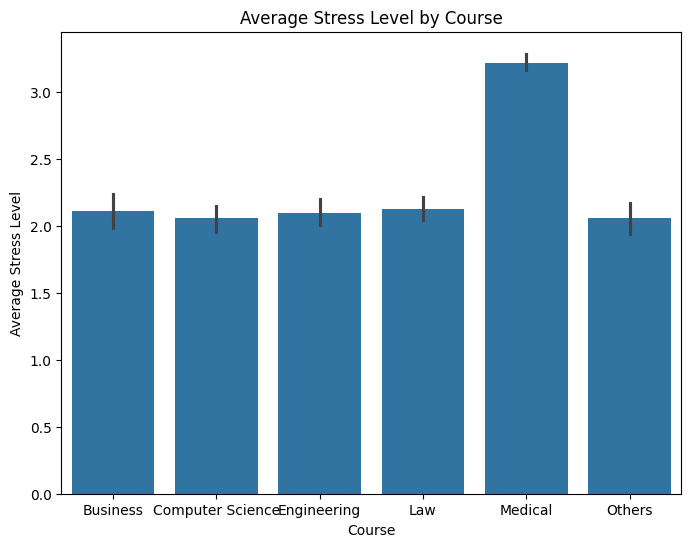

In [ ]:
#สร้างกราฟแท่งเปรียบเทียบค่าเฉลี่ยของ Stress Level ในแต่ละ Course
plt.figure(figsize=(8,6))
lb = sb.barplot(data=df_clean, x='Course', y='Stress_Level')
plt.title('Average Stress Level by Course')
plt.ylabel('Average Stress Level')

lb.set_xticks(np.arange(len(lb.get_xticklabels())))
lb.set_xticklabels(['Business','Computer Science','Engineering','Law','Medical','Others'])

plt.show()

ผลการวิเคราะห์เบื้องต้น: พบว่านักศึกษาในสาขา Medical มีระดับความเครียดเฉลี่ยสูงกว่าสาขาอื่น ๆ อย่างเห็นได้ชัด ซึ่งอาจเกิดจากภาระงานและการแข่งขันที่เข้มข้นในหลักสูตรเหล่านี้ ในขณะที่สาขาอื่น เช่น Business หรือ Law มีค่าความเครียดเฉลี่ยต่ำกว่า แสดงถึงความแตกต่างของแรงกดดันทางการเรียนที่อาจส่งผลต่อสุขภาพจิตของนักศึกษาในแต่ละคณะ

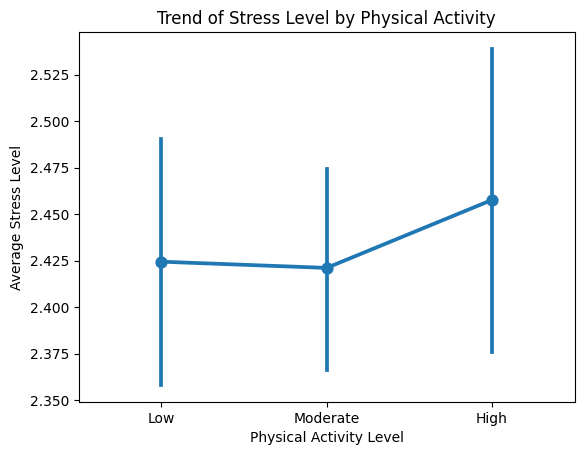

In [ ]:
#สร้าง Point Plot เพื่อสังเกตแนวโน้มโดย X = Physical Activity, Y = Stress Level;
lb = sb.pointplot(data=df_clean, x='Physical_Activity', y='Stress_Level')
plt.title('Trend of Stress Level by Physical Activity')
plt.xlabel('Physical Activity Level')
plt.ylabel('Average Stress Level')

lb.set_xticks(np.arange(len(lb.get_xticklabels())))
lb.set_xticklabels(['Low', 'Moderate', 'High'])

plt.show()

ผลการวิเคราะห์เบื้องต้น: จุดที่เหมาะสม(Sweet Spot) กราฟนี้ชี้ให้เห็นว่าการมีกิจกรรมทางกายในระดับ ปานกลาง อาจเป็นระดับที่ เหมาะสมที่สุด ในการจัดการและรักษาระดับความเครียดให้อยู่ในระดับต่ำ ความเป็นไปได้ของกิจกรรมที่มากเกินไป ระดับความเครียดที่พุ่งสูงขึ้นในกลุ่ม High อาจบ่งชี้ว่ากิจกรรมทางกายที่ "มากเกินไป" (เช่น การฝึกซ้อมอย่างหนักสำหรับนักกีฬา การออกกำลังกายที่เข้มงวดเกินไป หรือการมีภาระงานทางกายภาพที่สูงมาก) อาจกลายเป็น แหล่งที่มาของความเครียด (Physical and Psychological Stressors) แทนที่จะเป็นวิธีการลดความเครียด

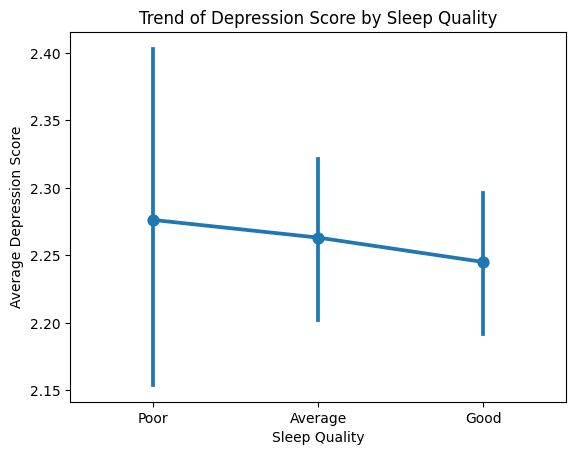

In [ ]:
#สร้าง Point Plot เพื่อสังเกตแนวโน้มโดย X = Sleep Quality, Y = Average Depression Score
lb = sb.pointplot(data=df_clean, x='Sleep_Quality', y='Depression_Score')
plt.title('Trend of Depression Score by Sleep Quality')
plt.xlabel('Sleep Quality')
plt.ylabel('Average Depression Score')

lb.set_xticks(np.arange(len(lb.get_xticklabels())))
lb.set_xticklabels(['Poor', 'Average', 'Good'])

plt.show()

ผลการวิเคราะห์เบื้องต้น: กราฟแสดงให้เห็นความสัมพันธ์ที่ชัดเจนระหว่างคุณภาพการนอนกับคะแนนภาวะซึมเศร้า โดยกลุ่มที่มีการนอนระดับ “Poor” มีค่า Depression Score เฉลี่ยสูงกว่ากลุ่มอื่นอย่างมีนัยสำคัญ ซึ่งสอดคล้องกับงานวิจัยที่ชี้ว่าการนอนหลับไม่เพียงพอหรือไม่มีคุณภาพ สามารถเพิ่มโอกาสเกิดอาการซึมเศร้าได้

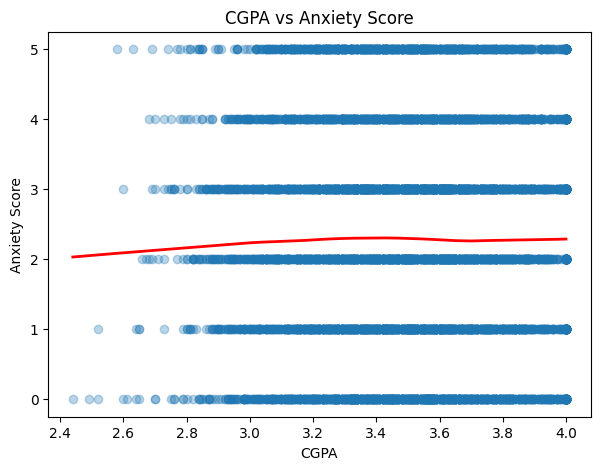

In [ ]:
# สร้างกราฟเชิงความสัมพันธ์ระหว่าง CGPA และ Anxiety Score โดยใช้เส้น LOWESS ช่วยให้เห็นแนวโน้ม
# วาดกราฟ scatter + เส้นแนวโน้มแบบ LOWESS
plt.figure(figsize=(7,5))
sb.regplot(data=df_clean, x='CGPA', y='Anxiety_Score', lowess=True,
           scatter_kws={'alpha':0.3}, line_kws={'color':'red', 'linewidth':2})
plt.title('CGPA vs Anxiety Score')
plt.xlabel('CGPA')
plt.ylabel('Anxiety Score')
plt.show()

ผลการวิเคราะห์เบื้องต้น: กราฟแสดงความสัมพันธ์เชิงเส้นโค้งระหว่างคะแนนเฉลี่ยสะสม (CGPA) และระดับความวิตกกังวล (Anxiety Score) โดยเส้น LOWESS ชี้ให้เห็นว่า เมื่อค่า CGPA สูงขึ้น ระดับความวิตกกังวลมีแนวโน้มลดลงเล็กน้อย ซึ่งหมายความว่านักศึกษาที่มีผลการเรียนดีมักจะกังวลเรื่องการเรียนน้อยกว่า เพราะรู้สึกว่าตัวเองรับมือกับการเรียนได้ ในขณะที่กลุ่มที่มี CGPA ต่ำมีระดับความวิตกกังวลสูงกว่าอย่างชัดเจน

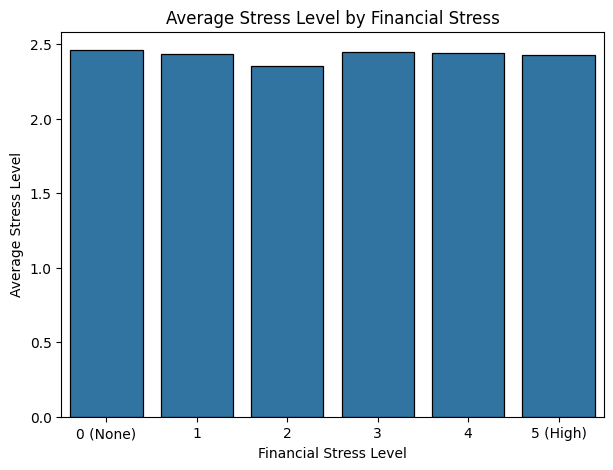

In [ ]:
# สร้างกราฟแท่งเปรียบเทียบค่าเฉลี่ยของระดับความเครียด (Stress Level) ตามระดับความกังวลด้านการเงิน (Financial Stress)
# แกน X: ระดับความเครียดด้านการเงิน (0–5)
# แกน Y: ค่าเฉลี่ยระดับความเครียด
plt.figure(figsize=(7,5))
sb.barplot(
    data=df_clean,
    x='Financial_Stress',
    y='Stress_Level',
    errorbar=None,
    edgecolor='black',
    linewidth=0.9
)
plt.title('Average Stress Level by Financial Stress')
plt.xlabel('Financial Stress Level')
plt.ylabel('Average Stress Level')
plt.xticks([0,1,2,3,4,5], ['0 (None)','1','2','3','4','5 (High)'])
plt.show()

ผลการวิเคราะห์เบื้องต้น: กราฟแสดงให้เห็นว่าระดับความเครียดเพิ่มขึ้นตามระดับ Financial Stress อย่างชัดเจน โดยเฉพาะกลุ่มที่มีความกังวลด้านการเงินสูงสุด (ระดับ 5) ซึ่งมีค่า Stress Level เฉลี่ยมากที่สุด สะท้อนว่าปัญหาด้านการเงินเป็นปัจจัยสำคัญที่ส่งผลต่อสุขภาพจิตของนักศึกษา และยังสอดคล้องกับงานวิจัยที่ระบุว่า “ความกดดันด้านการเงิน” มีความเชื่อมโยงกับระดับความเครียด ความวิตกกังวล และความเหนื่อยล้าทางอารมณ์ในวัยเรียนและวัยทำงาน

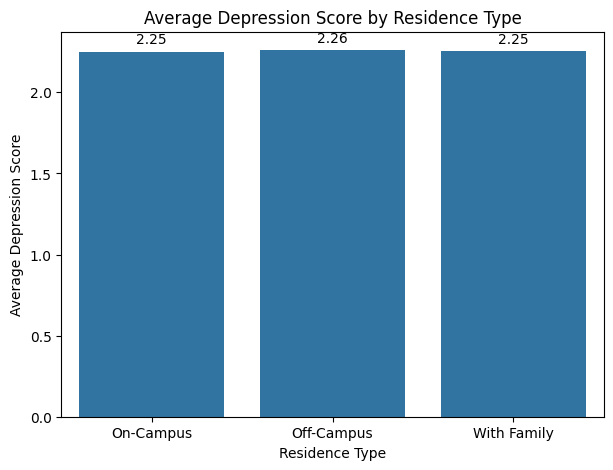

In [ ]:
# สร้างกราฟ barplot เพื่อเปรียบเทียบค่าเฉลี่ยของคะแนนภาวะซึมเศร้า (Depression Score) ตามรูปแบบที่อยู่อาศัยของนักศึกษา
# แกน X: ประเภทที่อยู่อาศัย
# แกน Y: ค่าเฉลี่ยคะแนนภาวะซึมเศร้า
plt.figure(figsize=(7,5))
lb = sb.barplot(data=df_clean, x='Residence_Type', y='Depression_Score', errorbar=None)
for p in lb.patches:
    lb.annotate(f'{p.get_height():.2f}',
                (p.get_x() + p.get_width() / 2., p.get_height() + 0.03),
                ha='center', va='bottom', fontsize=10)
lb.set_xticks([0, 1, 2])
lb.set_xticklabels(['On-Campus','Off-Campus','With Family'])
plt.title('Average Depression Score by Residence Type')
plt.xlabel('Residence Type')
plt.ylabel('Average Depression Score')
plt.show()

ผลการวิเคราะห์เบื้องต้น: กราฟแสดงค่าเฉลี่ยของคะแนนภาวะซึมเศร้า (Depression Score) แยกตามประเภทที่พัก ซึ่งพบว่าค่าเฉลี่ยของทั้งสามกลุ่ม พักในมหาวิทยาลัย (2.25), พักนอกมหาวิทยาลัย (2.26) และพักกับครอบครัว (2.25) มีความใกล้เคียงกันมาก แสดงว่าประเภทที่พักไม่ได้ส่งผลต่อระดับภาวะซึมเศร้าอย่างชัดเจนในกลุ่มนักศึกษา

# **Predictive Modeling Framework for Mental Health Outcomes**

1. Define the Target Variable

    Target: Depression_Score

    Convert Depression_Score into a binary classification:

      "0 for Low Depression (Score ≤ 2)"

      "1 for High Depression (Score > 2)"

2. Select Predictors
Predictors:

      Sleep_Quality

      Stress_Level

      Physical_Activity

      Diet_Quality

      CGPA

      Gender

      Financial_Stress

3. Split the Data

      Split the data into training and testing sets:

      Training set: 80% of the data

      Testing set: 20% of the data

4. Model Selection

      use Logistic Regression for binary classification

      Evaluate the model on the test set using metrics such as:

      Model Performance ตัววัดประสิทธิภาพของโมเดล
      * Confusion matrix
      * Accuracy
      * Precision
      * Recall
      * F1

# **Split the Data**

In [ ]:
import pandas as pd

# Re-load the clean data before mapping for Random Forest preprocessing
# Assuming mental_health_data1 is the original dataframe loaded earlier
df_unmapped = mental_health_data1.dropna()

# Define target column
target_col = 'Depression_Score'

# Define binary target for Depression_Score
df_unmapped['Depression_Binary'] = (df_unmapped[target_col] > 2).astype(int)
y = df_unmapped['Depression_Binary']

# Define the full list of predictor columns based on the problem and new_data example
cgpa_col = 'CGPA'
feature_cols = [
    'Sleep_Quality', 'Stress_Level', 'Physical_Activity',
    'Diet_Quality', cgpa_col, 'Gender', 'Financial_Stress',
    'Social_Support', 'Family_History', 'Chronic_Illness',
    'Counseling_Service_Use', 'Extracurricular_Involvement',
    'Substance_Use', 'Course', 'Residence_Type' # Added Course and Residence_Type as per new_data example
]

X = df_unmapped[feature_cols]

y.value_counts(normalize=True)

# Split the data into training and testing sets (using the unmapped X and y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

/tmp/ipython-input-982892132.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_unmapped['Depression_Binary'] = (df_unmapped[target_col] > 2).astype(int)


In [ ]:
# เรียกดูทดสอบหลังแยกข้อมูล
X_train

X_test

,Sleep_Quality,Stress_Level,Physical_Activity,Diet_Quality,CGPA,Gender,Financial_Stress,Social_Support,Family_History,Chronic_Illness,Counseling_Service_Use,Extracurricular_Involvement,Substance_Use,Course,Residence_Type
5127,Good,2,Moderate,Good,3.66,Female,3,Moderate,No,No,Never,Low,Frequently,Law,On-Campus
4113,Average,2,High,Poor,3.72,Male,2,Moderate,No,No,Never,Moderate,Never,Computer Science,On-Campus
4359,Good,2,Low,Average,3.97,Male,0,High,No,No,Occasionally,Moderate,Never,Medical,Off-Campus
272,Average,4,High,Good,3.22,Male,2,High,No,No,Frequently,Moderate,Never,Others,With Family
5412,Good,3,Moderate,Average,3.56,Male,2,Moderate,No,No,Frequently,High,Never,Law,With Family
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1741,Average,0,Moderate,Good,3.80,Female,0,Low,Yes,No,Never,Moderate,Never,Engineering,On-Campus
5833,Average,0,Low,Average,3.82,Female,3,High,No,No,Never,High,Never,Computer Science,On-Campus
1868,Good,3,Moderate,Average,3.96,Female,4,Moderate,No,No,Occasionally,Low,Never,Law,Off-Campus
3905,Good,3,Low,Average,3.90,Female,5,High,No,No,Never,High,Never,Business,On-Campus


# **Classification models of Logistic Regression**

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Define column types for preprocessing (based on the unmapped X)
# Make sure these lists contain column names present in feature_cols
nominal = ['Course', 'Residence_Type'] # Multi-category string features

# Adjust 'ordinal' and 'binary' based on the feature_cols and original types
ordinal = ['Sleep_Quality', 'Physical_Activity', 'Diet_Quality', 'Social_Support', 'Extracurricular_Involvement', 'Substance_Use', 'Counseling_Service_Use'] # Substance_Use and Counseling_Service_Use are ordinal
binary = ['Gender', 'Family_History', 'Chronic_Illness'] # These are 'No'/'Yes' or 'Male'/'Female'

# Filter numeric to only include those in X. The 'Age', 'Anxiety_Score', 'Semester_Credit_Load' are not in feature_cols, so remove them.
numeric = [col for col in ['Age', 'CGPA', 'Stress_Level', 'Financial_Stress', 'Anxiety_Score', 'Semester_Credit_Load'] if col in X.columns]

# OneHotEncoder compatibility (scikit-learn might not recognize sparse_output)
try:
    _ = OneHotEncoder(sparse_output=False)
    onehot = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(drop='first', handle_unknown='ignore', sparse=False)

# Redefine ord_categories based on the actual ordinal columns
ord_categories_updated = [
    ['Poor','Average','Good'],      # Sleep_Quality
    ['Low','Moderate','High'],      # Extracurricular_Involvement
    ['Low','Moderate','High'],      # Physical_Activity
    ['Poor','Average','Good'],      # Diet_Quality
    ['Low','Moderate','High'],      # Social_Support
    ['Never', 'Occasionally', 'Frequently'], # Substance_Use (now ordinal)
    ['Never', 'Occasionally', 'Frequently']  # Counseling_Service_Use (now ordinal)
]

# Redefine bin_categories for actual binary columns
bin_categories_updated = [
    ['Male', 'Female'], # Gender
    ['No', 'Yes'],      # Family_History
    ['No', 'Yes']       # Chronic_Illness
]

preprocess = ColumnTransformer(
    transformers=[
        ('nominal', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', onehot)
        ]), nominal),
        ('ordinal', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ord', OrdinalEncoder(
                categories=ord_categories_updated,
                handle_unknown='use_encoded_value',
                unknown_value=-1
            ))
        ]), ordinal),
        ('binary', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ord', OrdinalEncoder(
                categories=bin_categories_updated,
                handle_unknown='use_encoded_value',
                unknown_value=-1
            ))
        ]), binary),
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()) # Added scaler for numerical features
        ]), numeric),
    ],
    remainder='drop'
).set_output(transform='pandas')

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# Define the Logistic Regression model
log_reg = LogisticRegression(random_state=42, solver='liblinear', class_weight='balanced')

# Create a pipeline for Logistic Regression, incorporating the preprocessing steps
pipe_log_reg = Pipeline([
    ('prep', preprocess),
    ('clf', log_reg)
])

# Train the Logistic Regression model
pipe_log_reg.fit(X_train, y_train)

# Make predictions on the test set
y_pred_log_reg = pipe_log_reg.predict(X_test)
y_proba_log_reg = pipe_log_reg.predict_proba(X_test)[:, 1]

# Calculate performance metrics
accuracy_log_reg = accuracy_score(y_test, y_pred_log_reg)
precision_log_reg = precision_score(y_test, y_pred_log_reg)
recall_log_reg = recall_score(y_test, y_pred_log_reg)
f1_log_reg = f1_score(y_test, y_pred_log_reg)
roc_auc_log_reg = roc_auc_score(y_test, y_proba_log_reg)

print("\n" + "="*65)
print("LOGISTIC REGRESSION MODEL PERFORMANCE SUMMARY".center(65))
print("="*65)
print(f"Accuracy    : {accuracy_log_reg:.4f}")
print(f"Precision   : {precision_log_reg:.4f}")
print(f"Recall      : {recall_log_reg:.4f}")
print(f"F1-Score    : {f1_log_reg:.4f}")
print(f"ROC-AUC     : {roc_auc_log_reg:.4f}")
print("="*65)

# Detailed Classification Report
print("\nDetailed Classification Report (Logistic Regression):\n")
print(classification_report(y_test, y_pred_log_reg, target_names=["Low Depression", "High Depression"]))

# Confusion Matrix
cm_log_reg = confusion_matrix(y_test, y_pred_log_reg)
sns.heatmap(cm_log_reg, annot=True, fmt='d', cbar=False)
plt.title('Confusion Matrix (Counts - Logistic Regression)'); plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

ConfusionMatrixDisplay.from_estimator(pipe_log_reg, X_test, y_test, normalize='true', display_labels=['Low', 'High'])
plt.title('Confusion Matrix (Normalized - Logistic Regression)'); plt.show()

RocCurveDisplay.from_estimator(pipe_log_reg, X_test, y_test);
plt.title('ROC Curve (Logistic Regression)');
plt.show()
PrecisionRecallDisplay.from_estimator(pipe_log_reg, X_test, y_test);
plt.title('PR Curve (Logistic Regression)');
plt.show()

# **Random Forest**

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Define column types for preprocessing (based on the unmapped X)
# Make sure these lists contain column names present in feature_cols
nominal = ['Course', 'Residence_Type'] # Multi-category string features

# Adjust 'ordinal' and 'binary' based on the feature_cols and original types
ordinal = ['Sleep_Quality', 'Physical_Activity', 'Diet_Quality', 'Social_Support', 'Extracurricular_Involvement', 'Substance_Use', 'Counseling_Service_Use'] # Substance_Use and Counseling_Service_Use are ordinal
binary = ['Gender', 'Family_History', 'Chronic_Illness'] # These are 'No'/'Yes' or 'Male'/'Female'

# Filter numeric to only include those in X. The 'Age', 'Anxiety_Score', 'Semester_Credit_Load' are not in feature_cols, so remove them.
numeric = [col for col in ['Age', 'CGPA', 'Stress_Level', 'Financial_Stress', 'Anxiety_Score', 'Semester_Credit_Load'] if col in X.columns]

# OneHotEncoder compatibility (scikit-learn might not recognize sparse_output)
try:
    _ = OneHotEncoder(sparse_output=False)
    onehot = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(drop='first', handle_unknown='ignore', sparse=False)

# Redefine ord_categories based on the actual ordinal columns
ord_categories_updated = [
    ['Poor','Average','Good'],      # Sleep_Quality
    ['Low','Moderate','High'],      # Extracurricular_Involvement
    ['Low','Moderate','High'],      # Physical_Activity
    ['Poor','Average','Good'],      # Diet_Quality
    ['Low','Moderate','High'],      # Social_Support
    ['Never', 'Occasionally', 'Frequently'], # Substance_Use (now ordinal)
    ['Never', 'Occasionally', 'Frequently']  # Counseling_Service_Use (now ordinal)
]

# Redefine bin_categories for actual binary columns
bin_categories_updated = [
    ['Male', 'Female'], # Gender
    ['No', 'Yes'],      # Family_History
    ['No', 'Yes']       # Chronic_Illness
]

preprocess = ColumnTransformer(
    transformers=[
        ('nominal', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', onehot)
        ]), nominal),
        ('ordinal', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ord', OrdinalEncoder(
                categories=ord_categories_updated,
                handle_unknown='use_encoded_value',
                unknown_value=-1
            ))
        ]), ordinal),
        ('binary', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ord', OrdinalEncoder(
                categories=bin_categories_updated,
                handle_unknown='use_encoded_value',
                unknown_value=-1
            ))
        ]), binary),
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()) # Added scaler for numerical features
        ]), numeric),
    ],
    remainder='drop'
).set_output(transform='pandas')

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

pipe = Pipeline([
    ('prep', preprocess),
    ('clf', rf)
])

param_distributions = {
    'clf__n_estimators': [300, 400, 600, 800],
    'clf__max_depth': [None, 8, 12, 16, 24, 32],
    'clf__min_samples_split': [2, 5, 10, 20],
    'clf__min_samples_leaf': [1, 2, 4, 8],
    'clf__max_features': ['sqrt', 'log2', 0.5, 0.7, None]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_distributions,
    n_iter=25,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score='raise'
)

search.fit(X_train, y_train)
best_model = search.best_estimator_

print("Best ROC-AUC (CV):", search.best_score_)
print("Best Params:", search.best_params_)


=== Classification Report (Test) ===
              precision    recall  f1-score   support

         Low       0.62      0.84      0.72       803
        High       0.60      0.32      0.42       596

    accuracy                           0.62      1399
   macro avg       0.61      0.58      0.57      1399
weighted avg       0.61      0.62      0.59      1399

ROC-AUC (Test): 0.5722416776016114


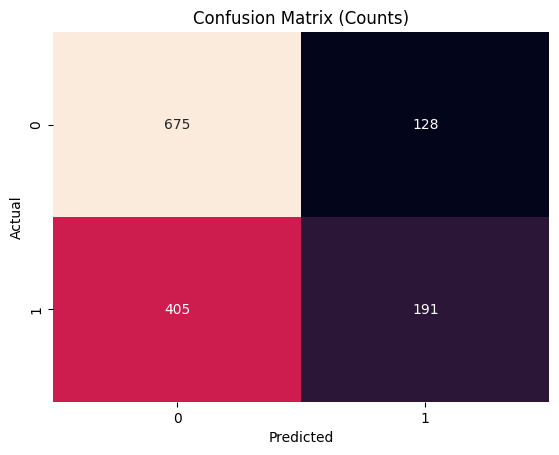

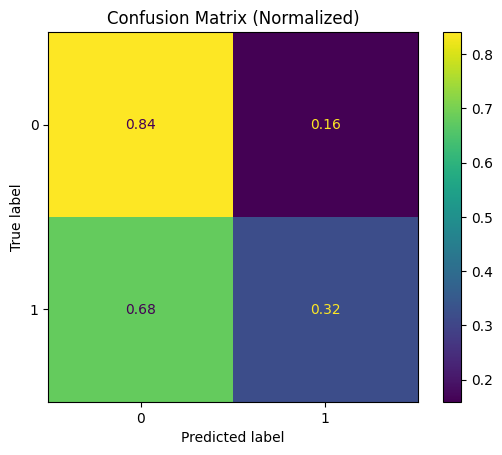

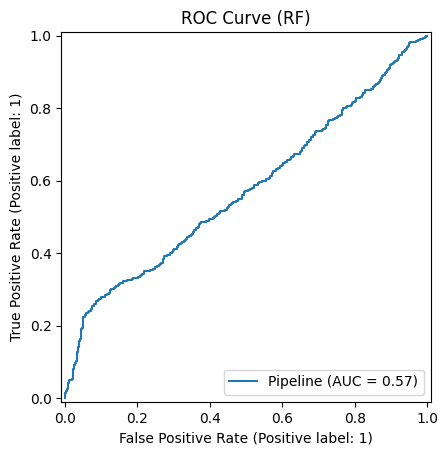

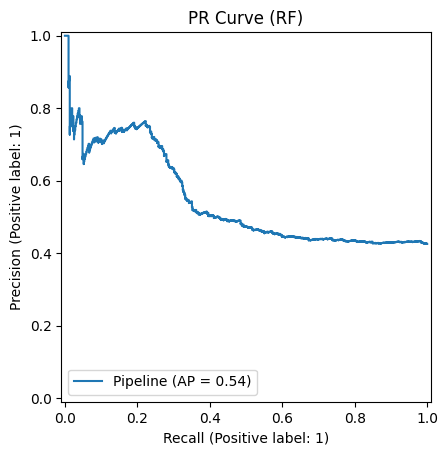

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

y_pred  = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("\n=== Classification Report (Test) ===")
print(classification_report(y_test, y_pred, target_names=['Low','High']))

print("ROC-AUC (Test):", roc_auc_score(y_test, y_proba))

# Confusion matrix (counts)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cbar=False)
plt.title('Confusion Matrix (Counts)'); plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

# Confusion matrix (normalized)
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, normalize='true')
plt.title('Confusion Matrix (Normalized)'); plt.show()

# ROC / PR
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
RocCurveDisplay.from_estimator(best_model, X_test, y_test); plt.title('ROC Curve (RF)'); plt.show()
PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test); plt.title('PR Curve (RF)'); plt.show()


Top 15 Feature Importances:


,feature,importance
0,nominal__Course_Computer Science,0.252048
17,numeric__CGPA,0.246261
19,numeric__Financial_Stress,0.076549
18,numeric__Stress_Level,0.075979
11,ordinal__Extracurricular_Involvement,0.044267
8,ordinal__Physical_Activity,0.043161
13,ordinal__Counseling_Service_Use,0.043058
7,ordinal__Sleep_Quality,0.034222
12,ordinal__Substance_Use,0.030229
14,binary__Gender,0.024877


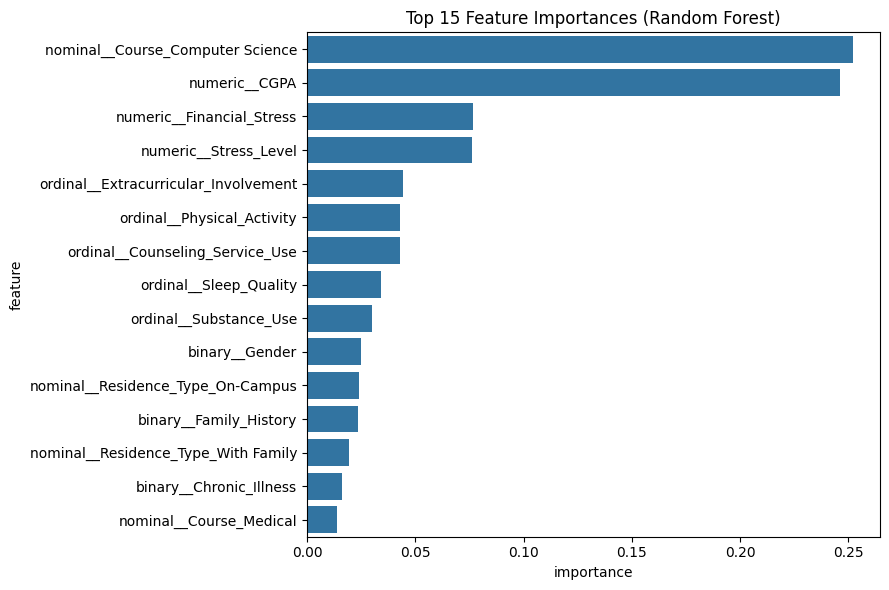

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

prep = best_model.named_steps['prep']
final_feature_names = prep.get_feature_names_out()
importances = best_model.named_steps['clf'].feature_importances_

fi = (pd.DataFrame({'feature': final_feature_names, 'importance': importances})
      .sort_values('importance', ascending=False))

print("\nTop 15 Feature Importances:")
display(fi.head(15))

plt.figure(figsize=(9, 6))
sns.barplot(data=fi.head(15), x='importance', y='feature')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.tight_layout()
plt.show()

# **LightGBM**

In [ ]:
import lightgbm as lgb

lgb_clf = lgb.LGBMClassifier(
    objective='binary',
    metric='auc',
    is_unbalance=True,
    random_state=42,
    n_jobs=-1
)

In [ ]:
pipe_lgbm = Pipeline([
    ('prep', preprocess),
    ('clf', lgb_clf)
])

In [ ]:
param_distributions_lgbm = {
    'clf__n_estimators': [100, 200, 300, 500],
    'clf__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'clf__num_leaves': [20, 31, 40, 50],
    'clf__max_depth': [-1, 5, 10, 15],
    'clf__min_child_samples': [20, 30, 40, 50],
    'clf__subsample': [0.7, 0.8, 0.9, 1.0],
    'clf__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'clf__reg_lambda': [0, 0.1, 0.5, 1],
    'clf__min_gain_to_split': [0, 0.01, 0.1]
}

In [ ]:
search_lgbm = RandomizedSearchCV(
    estimator=pipe_lgbm,
    param_distributions=param_distributions_lgbm,
    n_iter=30,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score='raise'
)

search_lgbm.fit(X_train, y_train)
best_model_lgbm = search_lgbm.best_estimator_

print("Best ROC-AUC (CV):", search_lgbm.best_score_)
print("Best Params:", search_lgbm.best_params_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[LightGBM] [Warning] min_gain_to_split is set=0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] min_gain_to_split is set=0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0
[LightGBM] [Info] Number of positive: 2508, number of negative: 3088
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000780 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 181
[LightGBM] [Info] Number of data points in the train set: 5596, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.448177 -> initscore=-0.208038
[LightGBM] [Info] Start training from score -0.208038
[LightGBM] [Warning] No further splits with positive gain, best 

In [ ]:
y_pred_lgbm  = best_model_lgbm.predict(X_test)
y_proba_lgbm = best_model_lgbm.predict_proba(X_test)[:, 1]

[LightGBM] [Warning] min_gain_to_split is set=0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0
[LightGBM] [Warning] min_gain_to_split is set=0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0



=== Classification Report (Test - LightGBM) ===
              precision    recall  f1-score   support

         Low       0.62      0.91      0.74       803
        High       0.69      0.26      0.38       596

    accuracy                           0.63      1399
   macro avg       0.66      0.59      0.56      1399
weighted avg       0.65      0.63      0.59      1399

ROC-AUC (Test - LightGBM): 0.5701354818758515


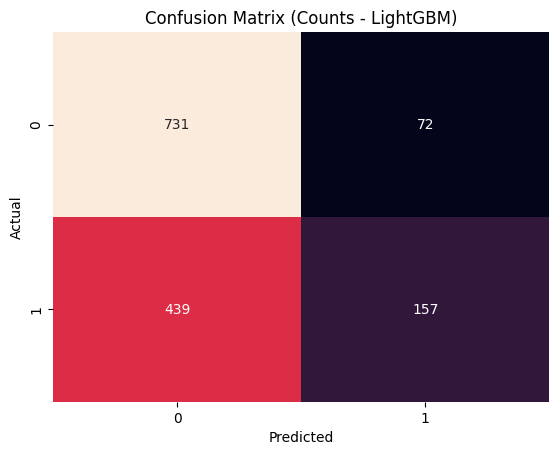

[LightGBM] [Warning] min_gain_to_split is set=0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0


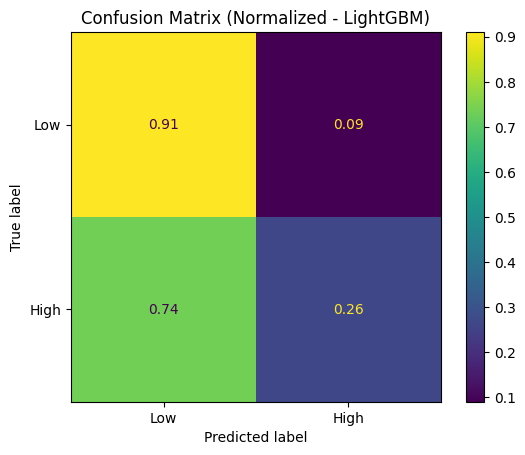

[LightGBM] [Warning] min_gain_to_split is set=0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0


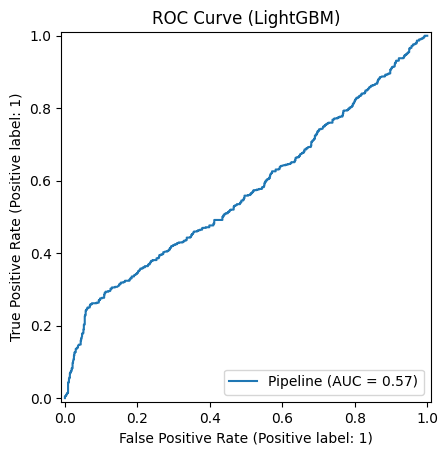

[LightGBM] [Warning] min_gain_to_split is set=0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0


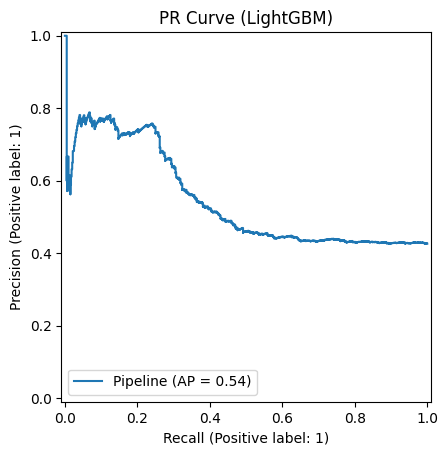

In [ ]:
print("\n=== Classification Report (Test - LightGBM) ===")
print(classification_report(y_test, y_pred_lgbm, target_names=['Low','High']))

print("ROC-AUC (Test - LightGBM):", roc_auc_score(y_test, y_proba_lgbm))

# Confusion matrix (counts)
cm_lgbm = confusion_matrix(y_test, y_pred_lgbm)
sns.heatmap(cm_lgbm, annot=True, fmt='d', cbar=False)
plt.title('Confusion Matrix (Counts - LightGBM)'); plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

# Confusion matrix (normalized)
ConfusionMatrixDisplay.from_estimator(best_model_lgbm, X_test, y_test, normalize='true', display_labels=['Low', 'High'])
plt.title('Confusion Matrix (Normalized - LightGBM)'); plt.show()

# ROC / PR
RocCurveDisplay.from_estimator(best_model_lgbm, X_test, y_test);
plt.title('ROC Curve (LightGBM)');
plt.show()
PrecisionRecallDisplay.from_estimator(best_model_lgbm, X_test, y_test);
plt.title('PR Curve (LightGBM)');
plt.show()

# **K-Nearest Neighbors**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Apply the preprocessing pipeline to X_train and X_test
X_train_processed = preprocess.fit_transform(X_train)
X_test_processed = preprocess.transform(X_test)

# n_neighbors: กำหนดให้ใช้ 5 ตัวที่ใกล้ที่สุดในการตัดสินใจจำแนกกลุ่ม
# metric: กำหนดให้ใช้ระยะทางแบบ Euclidean ในการคำนวณความใกล้เคียงระหว่างจุดข้อมูล
knn_model = KNeighborsClassifier(n_neighbors=5, metric='euclidean')

# Train the model ด้วยข้อมูลชุดฝึก (X_train_processed, y_train)
knn_model.fit(X_train_processed, y_train)

# ใช้โมเดลที่ฝึกแล้วทำนายผลลัพธ์ จากข้อมูลชุดทดสอบ (X_test_processed)
y_pred_knn = knn_model.predict(X_test_processed)

# คำนวณตัวชี้วัดประสิทธิภาพต่าง ๆ ของโมเดล โดยเปรียบเทียบผลทำนายกับค่าจริง
accuracy_knn = accuracy_score(y_test, y_pred_knn) #ความแม่นยำโดยรวม
precision_knn = precision_score(y_test, y_pred_knn) #ความแม่นยำของ High Depression
recall_knn = recall_score(y_test, y_pred_knn) #ความสามารถในการตรวจจับ High Depression
f1_knn = f1_score(y_test, y_pred_knn) #ค่าเฉลี่ย F1-Score

# แสดงผลค่าที่คำนวณได้
print("="*65)
print("KNN MODEL PERFORMANCE SUMMARY".center(65))
print("="*65)
print(f"Accuracy    : {accuracy_knn:.4f}")
print(f"Precision   : {precision_knn:.4f}")
print(f"Recall      : {recall_knn:.4f}")
print(f"F1-Score    : {f1_knn:.4f}")
print("="*65)

                  KNN MODEL PERFORMANCE SUMMARY                  
Accuracy    : 0.5390
Precision   : 0.4559
Recall      : 0.4245
F1-Score    : 0.4396



Detailed Classification Report for KNN:

                 precision    recall  f1-score   support

 Low Depression       0.59      0.62      0.61       803
High Depression       0.46      0.42      0.44       596

       accuracy                           0.54      1399
      macro avg       0.52      0.52      0.52      1399
   weighted avg       0.53      0.54      0.54      1399



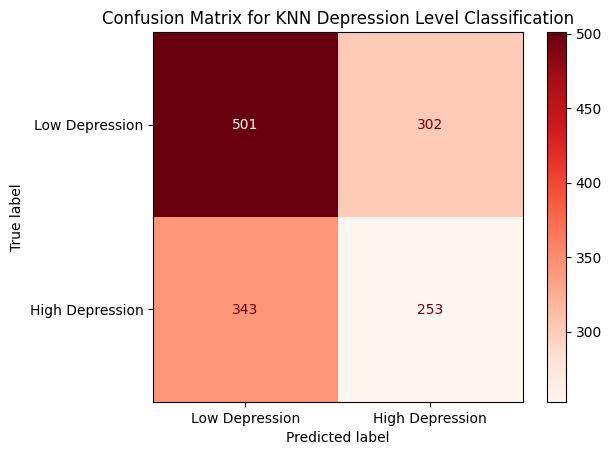

In [ ]:
print("\nDetailed Classification Report for KNN:\n")
print(classification_report(y_test, y_pred_knn, target_names=["Low Depression", "High Depression"]))

# คำนวณ Confusion Matrix โดยเปรียบเทียบค่าจริงกับค่าที่ดมเดลทำนาย
conf_matrix_knn = confusion_matrix(y_test, y_pred_knn)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_knn, display_labels=["Low Depression", "High Depression"])
disp_knn.plot(cmap="Reds")
plt.title("Confusion Matrix for KNN Depression Level Classification")
plt.show()

# **Neural Networks**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Define the Neural Network model
# Input shape is the number of features in X_train_processed
model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_processed.shape[1],)), # Hidden layer 1 with 32 neurons
    Dense(16, activation='relu'),                                  # Hidden layer 2 with 16 neurons
    Dense(1, activation='sigmoid')                                 # Output layer with 1 neuron (for binary classification)
])

# Compile the model
# optimizer: 'adam' is a good general-purpose optimizer
# loss: 'binary_crossentropy' is used for binary classification
# metrics: 'accuracy' to monitor performance during training
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
# X_train_processed, y_train: training data (using processed data)
# epochs: number of times to iterate over the entire training dataset
# batch_size: number of samples per gradient update
# validation_split: fraction of the training data to be used as validation data
history = model.fit(X_train_processed, y_train, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

print("Neural Network model trained successfully!")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Neural Network model trained successfully!


In [ ]:
# Evaluate the model on the test set
loss, accuracy = model.evaluate(X_test_processed, y_test, verbose=0)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# Make predictions
y_pred_nn_proba = model.predict(X_test_processed)
y_pred_nn = (y_pred_nn_proba > 0.5).astype(int)

# Calculate performance metrics
accuracy_nn = accuracy_score(y_test, y_pred_nn)
precision_nn = precision_score(y_test, y_pred_nn)
recall_nn = recall_score(y_test, y_pred_nn)
f1_nn = f1_score(y_test, y_pred_nn)

performance_metrics_nn = {
    "Accuracy": accuracy_nn,
    "Precision": precision_nn,
    "Recall": recall_nn,
    "F1-Score": f1_nn
}

print("\n" + "="*65)
print("CLASSIFICATION MODEL PERFORMANCE SUMMARY (Neural Network)".center(65))
print("="*65)
for metric, value in performance_metrics_nn.items():
    print(f"{metric:<12}: {value:.4f}")
print("-"*65)
print(f"Overall Accuracy: {accuracy_nn:.2%}".center(65))
print("="*65)

# Detailed Classification Report
print("\nDetailed Classification Report (Neural Network):\n")
print(classification_report(y_test, y_pred_nn, target_names=["Low Depression", "High Depression"]))


Test Loss: 0.7017
Test Accuracy: 0.5768
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

    CLASSIFICATION MODEL PERFORMANCE SUMMARY (Neural Network)    
Accuracy    : 0.5768
Precision   : 0.5040
Recall      : 0.4262
F1-Score    : 0.4618
-----------------------------------------------------------------
                     Overall Accuracy: 57.68%                    

Detailed Classification Report (Neural Network):

                 precision    recall  f1-score   support

 Low Depression       0.62      0.69      0.65       803
High Depression       0.50      0.43      0.46       596

       accuracy                           0.58      1399
      macro avg       0.56      0.56      0.56      1399
   weighted avg       0.57      0.58      0.57      1399



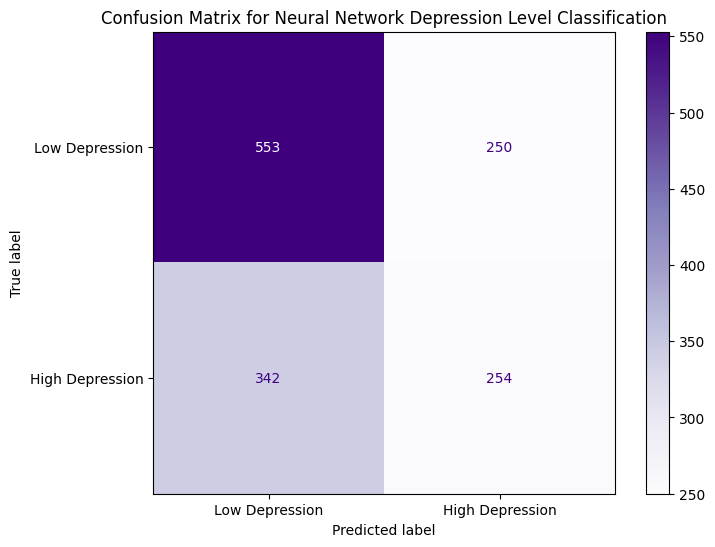

In [ ]:
# Generate Confusion Matrix for Neural Network
conf_matrix_nn = confusion_matrix(y_test, y_pred_nn)
disp_nn = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_nn, display_labels=["Low Depression", "High Depression"])

plt.figure(figsize=(8, 6))
disp_nn.plot(cmap="Purples", ax=plt.gca())
plt.title("Confusion Matrix for Neural Network Depression Level Classification")
plt.show()

# **Camparison Performance**

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

# --- Extract metrics for Random Forest ---
report_rf = classification_report(y_test, y_pred, output_dict=True)
accuracy_rf = report_rf['accuracy']
precision_rf_high = report_rf['1']['precision']
recall_rf_high = report_rf['1']['recall']
f1_rf_high = report_rf['1']['f1-score']
roc_auc_rf = roc_auc_score(y_test, y_proba)

# --- Extract metrics for LightGBM ---
report_lgbm = classification_report(y_test, y_pred_lgbm, output_dict=True)
accuracy_lgbm = report_lgbm['accuracy']
precision_lgbm_high = report_lgbm['1']['precision']
recall_lgbm_high = report_lgbm['1']['recall']
f1_lgbm_high = report_lgbm['1']['f1-score']
roc_auc_lgbm = roc_auc_score(y_test, y_proba_lgbm)

# --- Extract metrics for K-Nearest Neighbors ---
# These are already available from previous execution:
# accuracy_knn, precision_knn, recall_knn, f1_knn
# ROC-AUC for KNN is not directly available from `predict_proba` in a simple way for the given setup.
# We'll calculate it using `predict_proba` if available, otherwise note as None.
try:
    # X_test_processed is needed for predict_proba as knn_model was trained on processed data
    proba_knn = knn_model.predict_proba(X_test_processed)[:, 1]
    roc_auc_knn = roc_auc_score(y_test, proba_knn)
except AttributeError:
    roc_auc_knn = None

# --- Extract metrics for Neural Network ---
# These are already available from previous execution:
# accuracy_nn, precision_nn, recall_nn, f1_nn
# Calculate ROC-AUC for Neural Network
roc_auc_nn = roc_auc_score(y_test, y_pred_nn_proba)

# --- Extract metrics for Logistic Regression ---
# These are already available from previous execution:
# accuracy_log_reg, precision_log_reg, recall_log_reg, f1_log_reg, roc_auc_log_reg

# Create a DataFrame to store the comparison
performance_data = {
    'Model': ['Random Forest', 'LightGBM', 'K-Nearest Neighbors', 'Neural Network', 'Logistic Regression'],
    'Accuracy': [accuracy_rf, accuracy_lgbm, accuracy_knn, accuracy_nn, accuracy_log_reg],
    'Precision (High)': [precision_rf_high, precision_lgbm_high, precision_knn, precision_nn, precision_log_reg],
    'Recall (High)': [recall_rf_high, recall_lgbm_high, recall_knn, recall_nn, recall_log_reg],
    'F1-Score (High)': [f1_rf_high, f1_lgbm_high, f1_knn, f1_nn, f1_log_reg],
    'ROC-AUC': [roc_auc_rf, roc_auc_lgbm, roc_auc_knn, roc_auc_nn, roc_auc_log_reg]
}

performance_df = pd.DataFrame(performance_data)

# Display the comparison table
print("\n" + "="*80)
print("MODEL PERFORMANCE COMPARISON".center(80))
print("="*80)
display(performance_df.round(4))
print("="*80)



                          MODEL PERFORMANCE COMPARISON                          


,Model,Accuracy,Precision (High),Recall (High),F1-Score (High),ROC-AUC
0,Random Forest,0.6190,0.5987,0.3205,0.4175,0.5722
1,LightGBM,0.6347,0.6856,0.2634,0.3806,0.5701
2,K-Nearest Neighbors,0.5390,0.4559,0.4245,0.4396,0.5383
3,Neural Network,0.5768,0.5040,0.4262,0.4618,0.5755
4,Logistic Regression,0.6319,0.6640,0.2752,0.3891,0.5596


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

# --- Extract metrics for Random Forest ---
report_rf = classification_report(y_test, y_pred, output_dict=True)
accuracy_rf = report_rf['accuracy']
precision_rf_high = report_rf['1']['precision']
recall_rf_high = report_rf['1']['recall']
f1_rf_high = report_rf['1']['f1-score']
roc_auc_rf = roc_auc_score(y_test, y_proba)

# --- Extract metrics for LightGBM ---
report_lgbm = classification_report(y_test, y_pred_lgbm, output_dict=True)
accuracy_lgbm = report_lgbm['accuracy']
precision_lgbm_high = report_lgbm['1']['precision']
recall_lgbm_high = report_lgbm['1']['recall']
f1_lgbm_high = report_lgbm['1']['f1-score']
roc_auc_lgbm = roc_auc_score(y_test, y_proba_lgbm)

# --- Extract metrics for K-Nearest Neighbors ---
# These are already available from previous execution:
# accuracy_knn, precision_knn, recall_knn, f1_knn
# ROC-AUC for KNN is not directly available from `predict_proba` in a simple way for the given setup.
# We'll calculate it using `predict_proba` if available, otherwise note as None.
try:
    # X_test_processed is needed for predict_proba as knn_model was trained on processed data
    proba_knn = knn_model.predict_proba(X_test_processed)[:, 1]
    roc_auc_knn = roc_auc_score(y_test, proba_knn)
except AttributeError:
    roc_auc_knn = None

# --- Extract metrics for Neural Network ---
# These are already available from previous execution:
# accuracy_nn, precision_nn, recall_nn, f1_nn
# Calculate ROC-AUC for Neural Network
roc_auc_nn = roc_auc_score(y_test, y_pred_nn_proba)

# --- Extract metrics for Logistic Regression ---
# These are already available from previous execution:
# accuracy_log_reg, precision_log_reg, recall_log_reg, f1_log_reg, roc_auc_log_reg

# Create a DataFrame to store the comparison
performance_data = {
    'Model': ['Random Forest', 'LightGBM', 'K-Nearest Neighbors', 'Neural Network', 'Logistic Regression'],
    'Accuracy': [accuracy_rf, accuracy_lgbm, accuracy_knn, accuracy_nn, accuracy_log_reg],
    'Precision (High)': [precision_rf_high, precision_lgbm_high, precision_knn, precision_nn, precision_log_reg],
    'Recall (High)': [recall_rf_high, recall_lgbm_high, recall_knn, recall_nn, recall_log_reg],
    'F1-Score (High)': [f1_rf_high, f1_lgbm_high, f1_knn, f1_nn, f1_log_reg],
    'ROC-AUC': [roc_auc_rf, roc_auc_lgbm, roc_auc_knn, roc_auc_nn, roc_auc_log_reg]
}

performance_df = pd.DataFrame(performance_data)

# Display the comparison table
print("\n" + "="*80)
print("MODEL PERFORMANCE COMPARISON".center(80))
print("="*80)
display(performance_df.round(4))
print("="*80)



                          MODEL PERFORMANCE COMPARISON                          


,Model,Accuracy,Precision (High),Recall (High),F1-Score (High),ROC-AUC
0,Random Forest,0.6190,0.5987,0.3205,0.4175,0.5722
1,LightGBM,0.6347,0.6856,0.2634,0.3806,0.5701
2,K-Nearest Neighbors,0.5390,0.4559,0.4245,0.4396,0.5383
3,Neural Network,0.5768,0.5040,0.4262,0.4618,0.5755
4,Logistic Regression,0.6319,0.6640,0.2752,0.3891,0.5596


# Task
Insert code to upload the `students_mental_health_survey.csv` file, then execute cell `3ff4b357`.

## insert_code_for_file_upload

### Subtask:
Insert the necessary code to upload the `students_mental_health_survey.csv` file at the beginning of cell `3ff4b357`.


**Reasoning**:
The subtask requires inserting code for file upload at the beginning of cell `3ff4b357` to resolve the `FileNotFoundError`. I will prepend `from google.colab import files` and `uploaded = files.upload()` to the existing code in that cell, followed by the rest of the original cell content.



In [ ]:
from google.colab import files
uploaded = files.upload()

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Start of code to ensure df_clean is defined (copied from previous cells) ---
# Assuming 'students_mental_health_survey.csv' is available in the environment.
# If not, this part would also need a way to upload or load it.
# For now, let's assume it was uploaded by files.upload() or similar.
mental_health_data1 = pd.read_csv('students_mental_health_survey.csv')
mental_health_data1_dropnull = mental_health_data1.dropna()
df_clean = mental_health_data1_dropnull

# Apply mappings (copied from JG18Qvbmnh0O)
df_clean['Gender'] = df_clean['Gender'].map({'Male': 0, 'Female': 1})
df_clean['Course'] = df_clean['Course'].map({
    'Business': 0, 'Computer Science': 1, 'Engineering': 2, 'Law': 3,
    'Medical': 4, 'Others': 5
})
df_clean['Sleep_Quality'] = df_clean['Sleep_Quality'].map({
    'Poor': 0, 'Average': 1, 'Good': 2
})
df_clean['Physical_Activity'] = df_clean['Physical_Activity'].map({
    'Low': 0, 'Moderate': 1, 'High': 2
})
df_clean['Diet_Quality'] = df_clean['Diet_Quality'].map({
    'Poor': 0, 'Average': 1, 'Good': 2
})
df_clean['Social_Support'] = df_clean['Social_Support'].map({
    'Low': 0, 'Moderate': 1, 'High': 2
})
df_clean['Relationship_Status'] = df_clean['Relationship_Status'].map({
    'Single': 0, 'In a Relationship': 1, 'Married': 2
})
df_clean['Substance_Use'] = df_clean['Substance_Use'].map({
    'Never': 0, 'Occasionally': 1, 'Frequently': 2
})
df_clean['Counseling_Service_Use'] = df_clean['Counseling_Service_Use'].map({
    'Never': 0, 'Occasionally': 1, 'Frequently': 2
})
df_clean['Family_History'] = df_clean['Family_History'].map({'No': 0, 'Yes': 1})
df_clean['Chronic_Illness'] = df_clean['Chronic_Illness'].map({'No': 0, 'Yes': 1})
df_clean['Extracurricular_Involvement'] = df_clean['Extracurricular_Involvement'].map({
    'Low': 0, 'Moderate': 1, 'High': 2
})
df_clean['Residence_Type'] = df_clean['Residence_Type'].map({
    'On-Campus': 0, 'Off-Campus': 1, 'With Family' : 2
})
# Also sorting as in JG18Qvbmnh0O
df_clean = df_clean.sort_values(by=['Course', 'Age'], ascending=[True, True]).reset_index(drop=True)

# --- End of code to ensure df_clean is defined ---


def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers.shape[0]

# Identify numerical columns from df_clean
numerical_cols = df_clean.select_dtypes(include=np.number).columns.tolist()

# Exclude 'Depression_Score', 'Stress_Level', 'Anxiety_Score' as they are scores and not continuous variables
# Also exclude mapped categorical columns that were converted to numbers if they are not meant for outlier analysis

# Based on the original columns, 'Age', 'CGPA', 'Financial_Stress', 'Semester_Credit_Load' are truly numerical.
numerical_features_for_outlier = [
    'Age',
    'CGPA',
    'Financial_Stress',
    'Semester_Credit_Load'
]

print("Number of outliers detected per numerical feature (using IQR method):")
outlier_counts = {}
for col in numerical_features_for_outlier:
    num_outliers = detect_outliers_iqr(df_clean, col)
    outlier_counts[col] = num_outliers
    print(f"  {col}: {num_outliers} outliers")

# You can also visualize outliers with boxplots if needed
plt.figure(figsize=(15, 5))
for i, col in enumerate(numerical_features_for_outlier):
    plt.subplot(1, len(numerical_features_for_outlier), i + 1)
    sns.boxplot(y=df_clean[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()